# Extraction et visualisation des données
## Installation des bibliothèques

In [2]:
import pandas as pd # Pandas est une bibliothèque puissante pour la manipulation et l'analyse de données, surtout sous forme de tableaux (DataFrames).
import numpy as np # NumPy est une bibliothèque fondamentale pour le calcul scientifique en Python
import matplotlib.pyplot as plt # Matplotlib est une bibliothèque de visualisation graphique
from statsmodels.tsa.seasonal import seasonal_decompose # seasonal_decompose permet de décomposer une série temporelle en ses composantes (tendance, saisonnalité, résidus)
from sklearn.linear_model import LinearRegression # Effectuer une régression linéaire pour modéliser la relation entre une variable dépendante et une ou plusieurs variables indépendantes


## Lecture des données

In [3]:
data = pd.read_csv('autoroute.csv', sep=";", index_col=0)
data.describe()

FileNotFoundError: [Errno 2] No such file or directory: 'autoroute.csv'

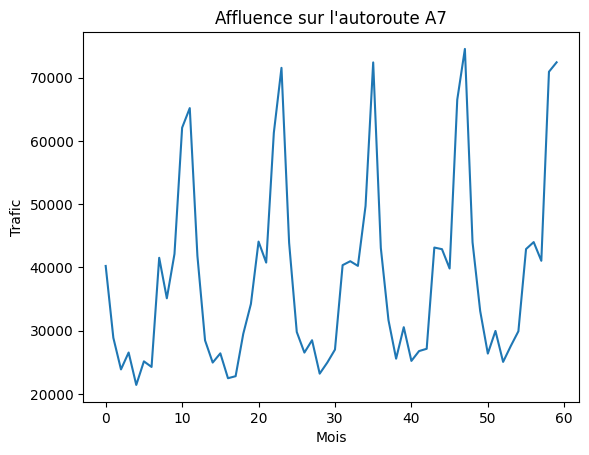

In [ ]:
# Extraction de la colonne d'intérêt (4ème colonne)
M = data.to_numpy()[:, 3]

# Séparation des données en ensembles d'apprentissage et de test
train = M[:60] 
test = M[60:-1] # On enlève le dernier mois sur les données test pour avoir des années complètes


# Visualisation des données, ajout des titres et labels
plt.plot(train)
plt.title("Affluence sur l'autoroute A7")
plt.xlabel("Mois")
plt.ylabel("Trafic")
plt.show()

# 1.
# Analyse du graphique : on peut observer une structure qui se répète à intervalles réguliers (des pics), la période est de 12 mois. De plus, on observe une tendance légèrement
# haussière sur les 5 années prises en compte. Ce n'est pas surprenant, cela pourrait correspondre aux mois de vacances estivales.

# Décomposition saisonnière

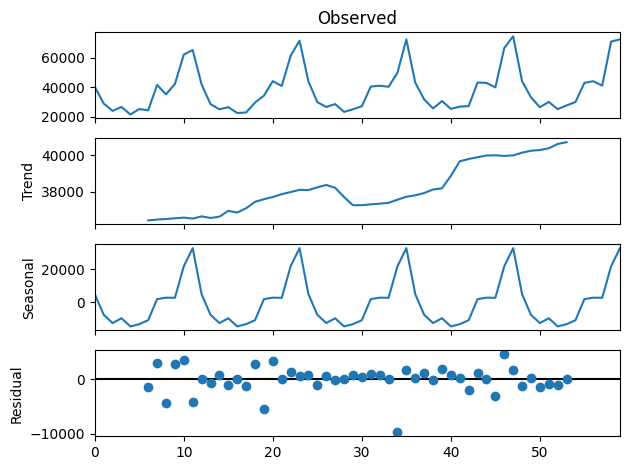

In [ ]:
decomp = seasonal_decompose(train, model='additive', period=12)
decomp.plot()

# Extraction de la tendance (en supprimant les valeurs NaN) 
tendance = decomp.trend[~np.isnan(decomp.trend)]

# 2.
# Nous avons appliqué un modèle additif avec une période de 12 mois, car l'amplitude des pics est globalement constante dans le temps.
# Cette décomposition permet d'isoler clairement la tendance à la hausse et la saisonnalité annuelle, tout en obtenant des résidus stables autour de zéro.


# Régression linéaire sur la tendance
## Préparation des données pour la régression linéaire

In [ ]:
time = np.arange(len(tendance)) + 6  # permet de mettre la valeur de time à 6 (et non pas 0 si on n'avait pas mis +6
time = time.reshape(-1, 1)  # Format adapté pour .fit car il lui faut un tableau 2D alors que time était un vecteur 1D

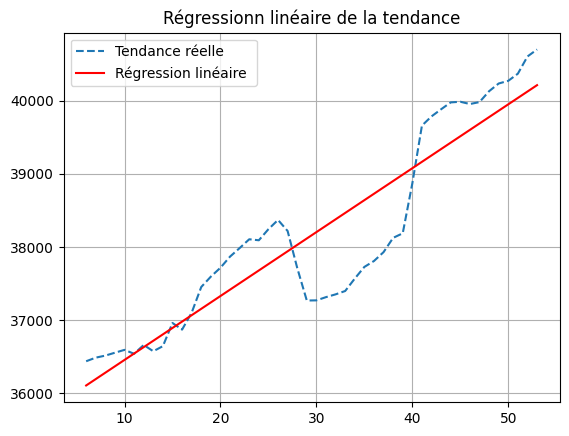

In [ ]:
model = LinearRegression() # Créé un objet régression linéaire
#Instanciation :
#Cette commande crée une instance (un objet) de la classe LinearRegression. model est le nom que vous donnez à cet objet. Vous pouvez utiliser n'importe quel nom (par exemple, regression, lr, etc.).
#À ce stade, le modèle est vide : il n'a pas encore été entraîné sur des données.

model.fit(time,tendance) # Ajuste un modèle linéaire de la tendance en fonction du temps
tendance_pred = model.predict(time)

# Coefficients de la régression y=ax+b
a = model.coef_[0] 
b = model.intercept_ 

# Affichage de la régression linéaire
# plt.figure(figsize=(10, 6)) par exemple, si l'on veut définir la taille de la figure largeur * hauteur
plt.plot(np.arange(len(tendance)) + 6, tendance, label="Tendance réelle ", linestyle="--")
plt.plot(np.arange(len(tendance)) + 6, tendance_pred, label="Régression linéaire ", color='red')
plt.legend()
plt.title("Régressionn linéaire de la tendance")
plt.grid(True)

# 3.
# Cette régression linéaire esr discutable, il y a un ecart de prédiction important (principalement entre le mois 28 et 40 ) 
# elle ne parvient pas à capter les dynamiques complexes de la tendance réelle.

# Prévision et comparaison

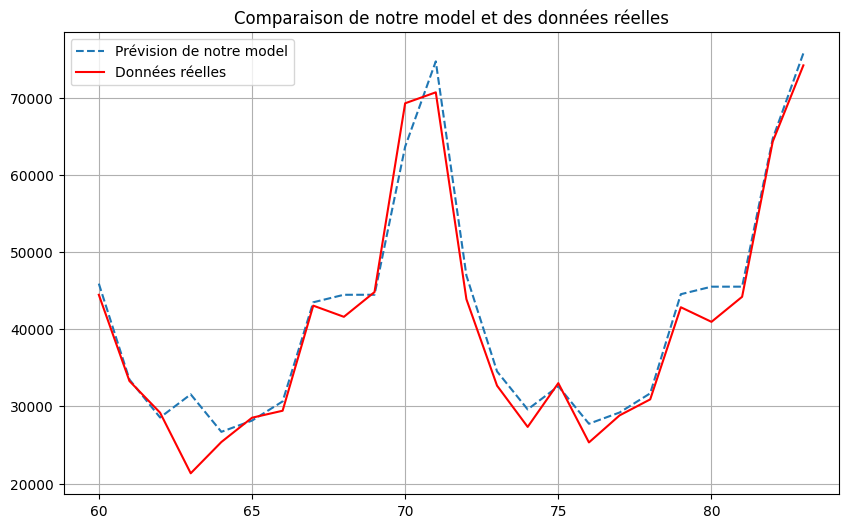

In [ ]:
# Prévision
time_prev = np.arange(60, 84) 

tendance_prev = a * time_prev + b
# Calcul de la tendance future en prolongeant la droite de régression (y = ax + b).

saison_prev = np.tile(decomp.seasonal[:12], 2)
# Création de la saisonnalité future en dupliquant le motif annuel de 12 mois sur 2 ans

prevision = tendance_prev + saison_prev
# Calcul de la prévision finale en additionnant la tendance et la saisonnalité (modèle additif).

# Comparaison avec les observations
plt.figure(figsize=(10, 6))
plt.plot(time_prev, prevision, label="Prévision de notre model", linestyle="--")
plt.plot(time_prev, test, label="Données réelles", color='red')
plt.legend()
plt.title("Comparaison de notre model et des données réelles")
plt.grid(True)

# Commentaire : notre model predit avec précision les données des 2 dernières années.Le modèle est très performant et parvient à reproduire fidèlement la dynamique des données réelles